# F.E. Walter: from weather to a daily reservoir decision

Follow the maintained 2016 configuration from `experiment.yaml` through
hydrology, the reservoir network, a Rule-based operator, and the two LLM
methods: **Rule-based**, **LLM without additional operating knowledge**, and **LLM with additional operating knowledge**. All three use the same inflow, initial state, and physical parameters.

This notebook reads committed files only. It makes no model request and runs no
hydrology or reservoir simulation.

Read the flow from weather through HydroCNHS to saved inflow, then reservoir operations.

![Weather to inflow workflow](../docs/figures/fe-walter-weather-workflow.svg)

[Maintained walkthrough](fe_walter.md) · [Current results](../examples/fe_walter/coupled/README.md#current-saved-2016-results)

## Setup

In [1]:
from pathlib import Path
import html, json, re, sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/hydrocnhs").is_dir())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from tutorials.build_notebooks import CMS_TO_CFS

class ReadableText:
    def __init__(self, title, text):
        self.title, self.text = title, text
    def _repr_markdown_(self):
        fence = "`" * max(4, 1 + max((len(run) for run in re.findall(r"`+", self.text)), default=0))
        return f"#### {self.title}\n\n{fence}text\n{self.text}\n{fence}"
    def _repr_html_(self):
        return f'<h4>{html.escape(self.title)}</h4><pre>{html.escape(self.text)}</pre>'

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25,
                     "font.family": "Arial", "font.size": 11, "axes.titlesize": 12,
                     "axes.labelsize": 11, "legend.fontsize": 11})

## 1. Start from the experiment file

The entry names the physical case, dates, output, agent file, hydrology file,
auditors, and extensions. The LLM entries change the agent and add a model
profile while retaining the same physical case and hydrology.

In [2]:
coupled = ROOT / "examples/fe_walter/coupled"
current_config = coupled
for title, name in (("Rule-based entry", "experiment.yaml"),
                    ("LLM without additional operating knowledge entry", "llm_available.yaml"),
                    ("LLM with additional operating knowledge entry", "llm_knowledge.yaml")):
    display(ReadableText(title, (current_config / name).read_text(encoding="utf-8")))

#### Rule-based entry

````text
# Rule-based teaching entry. Relative paths start from the file that declares them.
schema_version: hydroops-coupled-simulation.v2  # Loader format, not the package release.
run_id: fe-walter-current-rule                  # Label recorded in run metadata.
case: reservoirs.json                           # Physical reservoir and routing network JSON.
output: ../../../runs/fe-walter-current-rule    # Actual folder; change with run_id for a new run.
start_date: '2016-01-01'                        # First operation day (included).
end_date: '2016-12-31'                          # Last operation day (included).
# Run-wide provider-attempt ceiling; this rule makes no model calls.
max_calls: 0
# Agent, audit and hydrology settings are separate reusable layers.
agents:
  file: agents.rule.yaml
auditors:
  file: auditors.yaml
hydrology:
  file: hydrology.yaml
# Rules are generic registered modules; Hanasaki is this example's selected module.
extensions:
  hanasaki: ../../rules/hanasaki/__init__.py

````

#### LLM without additional operating knowledge entry

````text
# LLM entry using available operating information. Paths are relative to this file.
schema_version: hydroops-coupled-simulation.v2  # Loader format, not the package release.
case: reservoirs.json                           # Physical reservoir and routing network JSON.
start_date: '2016-01-01'                        # First operation day (included).
end_date: '2016-12-31'                          # Last operation day (included).
run_id: fe-walter-current-llm_available         # Label recorded in run metadata.
# Actual folder; change with run_id.
output: ../../../runs/fe-walter-current-llm_available
max_calls: null  # No run-wide provider-attempt cap; each profile still limits per-decision tries.
# Model, audit, agent and hydrology files remain distinct reusable layers.
models:
  file: models.yaml
auditors:
  file: auditors.yaml
agents:
  file: agents.llm_available.yaml
hydrology:
  file: hydrology.yaml
extensions:
  reference_v3_7: ../extensions/__init__.py  # Backend that interprets the agent parameters.

````

#### LLM with additional operating knowledge entry

````text
# LLM entry using the FE Walter knowledge file. Paths are relative to this file.
schema_version: hydroops-coupled-simulation.v2  # Loader format, not the package release.
case: reservoirs.json                           # Physical reservoir and routing network JSON.
start_date: '2016-01-01'                        # First operation day (included).
end_date: '2016-12-31'                          # Last operation day (included).
run_id: fe-walter-current-llm_knowledge         # Label recorded in run metadata.
# Actual folder; change with run_id.
output: ../../../runs/fe-walter-current-llm_knowledge
max_calls: null  # No run-wide provider-attempt cap; each profile still limits per-decision tries.
# Model, audit, agent and hydrology files remain distinct reusable layers.
models:
  file: models.yaml
auditors:
  file: auditors.yaml
agents:
  file: agents.llm_knowledge.yaml
hydrology:
  file: hydrology.yaml
extensions:
  reference_v3_7: ../extensions/__init__.py  # Backend that interprets the agent parameters.

````

## 2. Follow hydrology into the reservoir network

The accepted HydroCNHS model turns prepared weather and catchment inputs into
daily inflow. `hydrology.yaml` binds routed flow to `FEW_INFLOW`.
`reservoirs.json` maps it to node `FEWalter`, with physical case ID `fe_walter`.
Agent `fe_operator` must name graph node `FEWalter`.

![Reservoir and agent mapping](../docs/figures/reservoir-agent-mapping.svg)

In [3]:
hydrology = (coupled / "hydrology.yaml").read_text(encoding="utf-8")
case = json.loads((coupled / "reservoirs.json").read_text(encoding="utf-8"))
physical = case["network"]["reservoirs"]["FEWalter"]["physical"]
display(ReadableText("Complete hydrology.yaml", hydrology))
display(pd.DataFrame([{"inflow node": "FEW_INFLOW", "reservoir node": "FEWalter",
    "physical case ID": physical["reservoir_id"], "agent ID": "fe_operator",
    "initial storage (m³)": physical["initial_storage_m3"], "daily step (s)": physical["dt_seconds"]}]))

#### Complete hydrology.yaml

````text
# Hydrology layer. These paths are relative to this hydrology.yaml file.
# Accepted HydroCNHS model and warm-up interval.
model: ../../../data/accepted/fe_walter_hydrology.yaml
# Daily weather forcing.
forcing: ../../../data/accepted/fe_walter_forcing_1989_2025.csv.gz
# Native outlets listed here receive an explicit zero assigned flow during preparation.
zero_flow_nodes:
- __AGGREGATION_OUTLET__
# Every physical-network local-inflow node maps to one non-overlapping boundary in m3/s.
inflow_bindings:
  FEW_INFLOW:
    routed: __AGGREGATION_OUTLET__  # Routed HydroCNHS outlet feeding FE Walter.
  Downstream:
    constant: 0  # Explicit zero local lateral inflow; upstream release is routed separately.

````

,inflow node,reservoir node,physical case ID,agent ID,initial storage (m³),daily step (s)
0,FEW_INFLOW,FEWalter,fe_walter,fe_operator,2.457848e+06,86400.0


## 3. Change the decision method

The Rule-based agent selects a registered rule. The available-information LLM
receives daily state, seasonal instruction, and short history. The
retrieved-knowledge LLM adds selected operating guidance. Model identity and
sampling controls are settings and provenance, not method names.

![Prompt and context workflow](../docs/figures/prompt-context-workflow.svg)

In [4]:
for title, name in (("Rule-based agent", "agents.rule.yaml"),
                    ("LLM without additional operating knowledge agent", "agents.llm_available.yaml"),
                    ("LLM with additional operating knowledge agent", "agents.llm_knowledge.yaml")):
    display(ReadableText(title, (coupled / name).read_text(encoding="utf-8")))
display(ReadableText("Model settings and provenance", (current_config / "models.yaml").read_text(encoding="utf-8")))

#### Rule-based agent

````text
# Agent layer. fe_operator is the decision-unit ID used in plans and traces.
fe_operator:
  reservoir_id: FEWalter  # Controlled reservoir ID in reservoirs.json.
  type: rule_based        # Deterministic method: no model profile or provider.
  rule: hanasaki          # Generic registered rule ID; Hanasaki is this example's module.
  # Parameters belong to that module rather than to the core agent schema.
  rule_parameters:
    purpose: flood_control  # Hanasaki operating-purpose category.
    alpha: 0.85             # Dimensionless usable-capacity fraction (0, 1].
    # Relative to this file.
    inflow_statistics_file: ../../../data/benchmark/fe_walter_statistics.json
  # Auditor IDs refer to profiles in auditors.yaml.
  auditors:
  - release_limits

````

#### LLM without additional operating knowledge agent

````text
# Agent layer for the available-information method.
fe_operator:  # Decision-unit ID used in plans and traces.
  reservoir_id: FEWalter          # Controlled reservoir ID in reservoirs.json.
  type: llm                       # Provider-backed operating method.
  model_profile: reservoir_model  # Profile ID from models.yaml.
  customization:
    backend: reference_v3_7  # Registered backend ID from the entry's extensions.
    # The backend owns this reference recipe; the framework keeps it opaque.
    parameters:
      reference:
        profile: fe_walter           # Backend's FE Walter physical/operating profile.
        method: zeroshot             # Available-information method, without a DKP document.
        consultation_mode: daily     # One decision opportunity per operation day.
        response_validation: policy  # Validate replies with the backend policy contract.
        # Relative to this file.
        system_prompt: ../prompts/available_information.txt
        system_prompt_mode: custom  # Use the declared system-prompt file.
        # Daily study-defined pool window context.
        seasonal_criteria_file: ../seasonal_pool_criteria.json
        prompt_storage: false         # Do not include storage in the prompt representation.
        hide_availability_line: true  # Preserve the approved prompt variant.
        dkp_no_missing_inputs: true   # Reject incomplete backend inputs.
        zeroshot_knowledge: target    # Supply target-operation context, not a DKP file.
  # Auditor IDs refer to profiles in auditors.yaml.
  auditors:
  - release_limits

````

#### LLM with additional operating knowledge agent

````text
# Agent layer for the domain-knowledge method.
fe_operator:  # Decision-unit ID used in plans and traces.
  reservoir_id: FEWalter          # Controlled reservoir ID in reservoirs.json.
  type: llm                       # Provider-backed operating method.
  model_profile: reservoir_model  # Profile ID from models.yaml.
  customization:
    backend: reference_v3_7  # Registered backend ID from the entry's extensions.
    # The backend owns this reference recipe; the framework keeps it opaque.
    parameters:
      reference:
        profile: fe_walter           # Backend's FE Walter physical/operating profile.
        method: dkp                  # Include the declared domain-knowledge package.
        consultation_mode: daily     # One decision opportunity per operation day.
        response_validation: policy  # Validate replies with the backend policy contract.
        # Relative to this file.
        system_prompt: ../prompts/retrieved_knowledge.txt
        system_prompt_mode: custom  # Use the declared system-prompt file.
        # Daily study-defined pool window context.
        seasonal_criteria_file: ../seasonal_pool_criteria.json
        dkp: ../knowledge/operating_rules.md  # Knowledge document, relative to this file.
        prompt_storage: false                 # Do not include storage in the prompt representation.
        hide_availability_line: true          # Preserve the approved prompt variant.
        dkp_no_missing_inputs: true           # Reject incomplete backend inputs.
        zeroshot_knowledge: target            # Backend compatibility setting for target context.
  # Auditor IDs refer to profiles in auditors.yaml.
  auditors:
  - release_limits

````

#### Model settings and provenance

````text
# Shared provider profile. Agents select it with model_profile: reservoir_model.
reservoir_model:  # Reusable profile ID, separate from the provider's model name.
  provider: ollama                  # Local Ollama HTTP protocol.
  model: gemma4:12b                 # Exact model tag already installed in Ollama.
  base_url: http://localhost:11434  # Ollama server root; the loader adds /api/chat.
  temperature: 0.7                  # Dimensionless sampling control (0 to 2).
  max_tokens: 2048                  # Maximum generated tokens; sent to Ollama as num_predict.
  num_ctx: 16384                    # Ollama context-window size in tokens.
  think: false                      # Do not request Ollama's separate thinking output.
  keep_alive: 30m                   # How long Ollama keeps the model loaded after a request.
  seed: null                        # Use the provider default rather than a fixed integer seed.
  timeout_seconds: 120              # Timeout for each provider attempt, in seconds.
  api_key_env: null                 # No environment-variable credential for this local endpoint.
  max_attempts: 2                   # Total tries per decision, including the first try.
  retry_delay_seconds: 2            # Wait between retryable attempts, in seconds.

````

## 4. Inspect actual prompt and retrieved context

The saved pairs contain the exact request messages and replies. The parser
converts cfs to m³/s, then common physics enforces water availability and release
bounds. These records are examples from the saved run.

In [5]:
saved = coupled / "outputs/gemma4_2016_comparison"
labels = {"llm_available": "LLM without additional operating knowledge", "llm_knowledge": "LLM with additional operating knowledge"}
for method, label in labels.items():
    pair = json.loads((saved / f"{method}_pair.json").read_text(encoding="utf-8"))
    record = pair["engines"]["framework"]
    display(ReadableText(f"{label}: saved request messages",
                         json.dumps(record["provider_request"]["messages"], indent=2, ensure_ascii=False)))
    display(ReadableText(f"{label}: saved reply", record["raw_provider_reply"]["message"]["content"]))
    display(pd.DataFrame([{"method": label, "saved date": pair["date"],
                           "controlled release (cfs)": record["physics"]["controlled_release_cms"] * CMS_TO_CFS,
                           "end elevation (ft)": record["physics"]["pool_elevation_end_ft"]}]))

#### LLM without additional operating knowledge: saved request messages

````text
[
  {
    "role": "system",
    "content": "You are the operator of a reservoir, making one release decision per day.\n\nReservoir information (public sources):\n- Name: F.E. Walter Dam on the Lehigh River, Pennsylvania\n- Location: Bear Creek Township, Luzerne County and Kidder Township, Carbon County, Pennsylvania\n- Purpose: flood control, water storage, recreation\n- Opened: 1961; operated by the U.S. Army Corps of Engineers\n- Type: earth-fill embankment with rock shell, impounding the Lehigh River\n- Dam height (foundation): 234 ft; length: 3,000 ft\n- Spillway type: concrete\n- Catchment area: 289 square miles\n- Total capacity (publicly reported): 110,700 acre-feet\n- Operation target: Your goal is to keep the water level within the designated seasonal pool levels. From November 1 through March 14, keep the pool near the conservation pool at 1300.0 ft N.G.V.D., within 1297.0 to 1303.0 ft. From March 15 through May 9, keep the pool between 1300.0 and 1370.0 ft and, when hydrologic conditions allow, fill toward 1370.0 ft by May 10. From May 10 through October 14, keep the pool at or below 1370.0 ft. From October 15 through October 31, keep the pool between 1300.0 and 1370.0 ft and lower it toward 1300.0 ft by November 1.\n\nEach day you will receive the current date, mean inflow,\nwater level at the beginning of the interval, and the previous one or two\nsimulated release decisions.\nFlows are also stated as volumes in cubic feet over their interval, the\nunit of the water balance. Decide the interval's mean release\nin cfs, consistent with the reservoir's purpose. You have no operating\nmanual; use general reservoir-operation principles.\n\nPhysical water balance (not an operating rule):\n- storage_change_cubic_feet = (inflow_cfs - release_cfs) * 86,400 * interval_days.\n- A release below inflow increases storage; a release equal to inflow\n  leaves storage approximately unchanged; a release above inflow decreases\n  storage. Passing inflow cannot refill a reservoir below its target.\n\nConstraints you must respect:\n- Do not plan to release more water than is available (storage + inflow).\n- Avoid letting storage exceed capacity (uncontrolled spill).\n- Avoid abrupt interval-to-interval release changes unless conditions require them.\n\nRespond only with JSON, with the fields in this order:\n  applicable_target_ft (the operation-target water level for this interval),\n  pool_position (below_target | at_target | above_target),\n  intended_storage_direction (increase | hold | decrease),\n  release_relation_to_inflow (below_inflow | equal_to_inflow | above_inflow),\n  reasoning (1-2 sentences), release_cfs (number).\nDecide the first four, then write the reasoning, then choose release_cfs.\nMake release_cfs consistent with the four fields and with your reasoning."
  },
  {
    "role": "user",
    "content": "Date: 2016-01-02 (January, day 2 of the year)\n1. Today's inflow: 789.4 cfs (= 68,203,331 cubic feet (= 1,566 acre-feet) over 1 days)\n2. Water level at beginning of interval: 1300.00 ft NGVD29\n3. Previous simulated release decisions (and what was actually released):\n   2016-01-01: decided 1,134.5 cfs; actually released 1,134.5 cfs (= 98,020,800 cubic feet (= 2,250 acre-feet) over 1 days)\n4. Number of days in this decision interval: 1\n\nDecide the mean release for this interval (cfs)."
  }
]
````

#### LLM without additional operating knowledge: saved reply

````text
{
  "applicable_target_ft": 1300.0,
  "pool_position": "at_target",
  "intended_storage_direction": "hold",
  "release_relation_to_inflow": "equal_to_inflow",
  "reasoning": "The current water level is exactly at the target conservation pool. To maintain this level, the release should match the current inflow.",
  "release_cfs": 789.4
}
````

,method,saved date,controlled release (cfs),end elevation (ft)
0,LLM without additional operating knowledge,2016-01-02,789.400011,1299.999706


#### LLM with additional operating knowledge: saved request messages

````text
[
  {
    "role": "system",
    "content": "You are the water control manager operating F.E. Walter Dam on the Lehigh River, Pennsylvania,\nmaking one release decision per day.\n\nReservoir information (public sources):\n- Name: F.E. Walter Dam on the Lehigh River, Pennsylvania\n- Location: Bear Creek Township, Luzerne County and Kidder Township, Carbon County, Pennsylvania\n- Purpose: flood control, water storage, recreation\n- Opened: 1961; operated by the U.S. Army Corps of Engineers\n- Type: earth-fill embankment with rock shell, impounding the Lehigh River\n- Dam height (foundation): 234 ft; length: 3,000 ft\n- Spillway type: concrete\n- Catchment area: 289 square miles\n- Total capacity (publicly reported): 110,700 acre-feet\n- Operation target: Your goal is to keep the water level within the designated seasonal pool levels. From November 1 through March 14, keep the pool near the conservation pool at 1300.0 ft N.G.V.D., within 1297.0 to 1303.0 ft. From March 15 through May 9, keep the pool between 1300.0 and 1370.0 ft and, when hydrologic conditions allow, fill toward 1370.0 ft by May 10. From May 10 through October 14, keep the pool at or below 1370.0 ft. From October 15 through October 31, keep the pool between 1300.0 and 1370.0 ft and lower it toward 1300.0 ft by November 1.\n\nFrom the reservoir's water control manual:\n- Storage at spillway crest (el. 1450.0 ft): 109,878 acre-feet\n- Maximum allowable release: 10,000 cfs\n- Minimum required release: 50 cfs\n\nYour operating knowledge comes from the reservoir's Decision\nKnowledge Package (DKP), extracted from the project's official\nwater control manual. Each day, the sections of the DKP most\nrelevant to the current conditions are retrieved and provided to\nyou together with the system state. Base your decision on those\nretrieved DKP excerpts: apply their operating zones, decision\nrules, release constraints, rating tables, and seasonal guidance.\nThis model represents the reservoir only: storage, inflow and release.\nApply the storage, inflow, seasonal and release-limit rules.\nDo not invent an observation or rule.\n\nHow to apply the DKP in this simulation:\n- Storage-to-elevation conversion is physical preprocessing and the current\n  pool elevation may be supplied. Apply the shared operation target stated\n  in the reservoir information; do not derive a different target from the DKP.\n- Compare the current pool with that target yourself; no precomputed\n  above-target or below-target interpretation is supplied.\n- Gate-position rate limits are not discharge-rate limits. Do not convert\n  them to cfs per hour without the required gate-rating information.\n- Exhibit D's numerical recreation calendar is explicitly specific to 2014.\n  In every other year, apply only the structural recreation constraints\n  stated by the DKP and identify the annual calendar as unavailable; do not\n  transfer the 2014 weekday, weekend, event-date, or numeric release schedule.\n- No recommended release, target-tracking controller output, or precomputed\n  above/below-target label is supplied. Select the release independently\n  from the retrieved DKP rules and the raw state values.\n- If the DKP does not provide a unique numeric release for the available\n  inputs, do not invent an official formula. Choose the most defensible\n  action allowed by the retrieved rules and explain it in the reasoning.\n- No external reduced-domain release rule is supplied in this run.\n- Use store_toward_target or draw_toward_target only when the selected\n  release actually changes storage in that direction. Use pass_inflow only\n  when the selected release is approximately equal to inflow.\n- During seasonal refill, report store_toward_target; during seasonal\n  drawdown, report draw_toward_target. Reserve recreation_plan for an\n  applicable dated recreation-release instruction whose calendar is known.\n\nPhysical water 

#### LLM with additional operating knowledge: saved reply

````text
{
  "applicable_target_ft": 1300.0,
  "pool_position": "at_target",
  "intended_storage_direction": "hold",
  "release_relation_to_inflow": "equal_to_inflow",
  "operating_mode": "pass_inflow",
  "rules_applied": [
    "R-RELEASE",
    "R-MINNORM",
    "R-ATSITE",
    "R-ZONE"
  ],
  "reasoning": "The current date is January 2, which falls within the winter period (Nov 1 - Mar 14) where the target pool elevation is 1300.0 ft. The current pool elevation is exactly 1300.0 ft, which is at the target. According to R-RELEASE, for Plan A (maintaining pool at or near target), the release should equal the inflow. The inflow is 789.4 cfs. This release is well above the R-MINNORM of 50 cfs and below the R-ATSITE limit of 10,000 cfs. Since the goal is to hold the pool at the target level, passing the inflow exactly maintains the current elevation.",
  "release_cfs": 789.4
}
````

,method,saved date,controlled release (cfs),end elevation (ft)
0,LLM with additional operating knowledge,2016-01-02,789.400011,1299.999706


## 5. Compare the three current teaching trajectories

The builder combines Rule-based rows from `outputs/2016/daily.csv` with the two
framework LLM rows from `outputs/gemma4_2016_comparison/daily.csv`. It verifies
366 unique ordered dates per method, common inflow, shared initial state, and
units. It performs no interpolation. Four panels share operation dates:
(a) end-of-day water elevation in feet NGVD 29; (b–d) daily water release in cfs,
one method per panel. Water release means implemented controlled release and
excludes spill. Blue lines show the upstream simulated inflow on the same flow scale.
Release below inflow retains water; release above inflow draws from storage.
The seasonal reference switches vertically between the 1300 ft winter target and
1370 ft summer ceiling on May 15 and October 15. These mid-month markers summarize
seasonal targets, rather than daily physical water-level changes. Saved operation
and audit settings are unchanged. The source CSV retains m³/s.

In [6]:
current = coupled / "outputs/current_tutorial"
daily = pd.read_csv(current / "daily.csv")
seasonal_criteria = json.loads((ROOT / "examples/fe_walter/seasonal_pool_criteria.json").read_text(encoding="utf-8"))
provenance = json.loads((current / "provenance.json").read_text(encoding="utf-8"))
display(daily.assign(controlled_release_cfs=daily["controlled_release_cms"] * CMS_TO_CFS)
    .groupby("method_label", sort=False).agg(rows=("date", "size"),
    unique_dates=("date", "nunique"), maximum_release_cfs=("controlled_release_cfs", "max")))
display(pd.DataFrame(provenance["validation"]["methods"]).T)

,rows,unique_dates,maximum_release_cfs
method_label,,,
Rule-based,366,366,2918.578902
LLM without additional operating knowledge,366,366,3200.000046
LLM with additional operating knowledge,366,366,3744.600054


,rows,unique_dates,date_start,date_end,max_inflow_difference_from_reference_cms,initial_storage_m3
rule,366,366,2016-01-01,2016-12-31,0.0,2457848.279729
llm_available,366,366,2016-01-01,2016-12-31,0.0,2457848.279729
llm_knowledge,366,366,2016-01-01,2016-12-31,0.0,2457848.279729


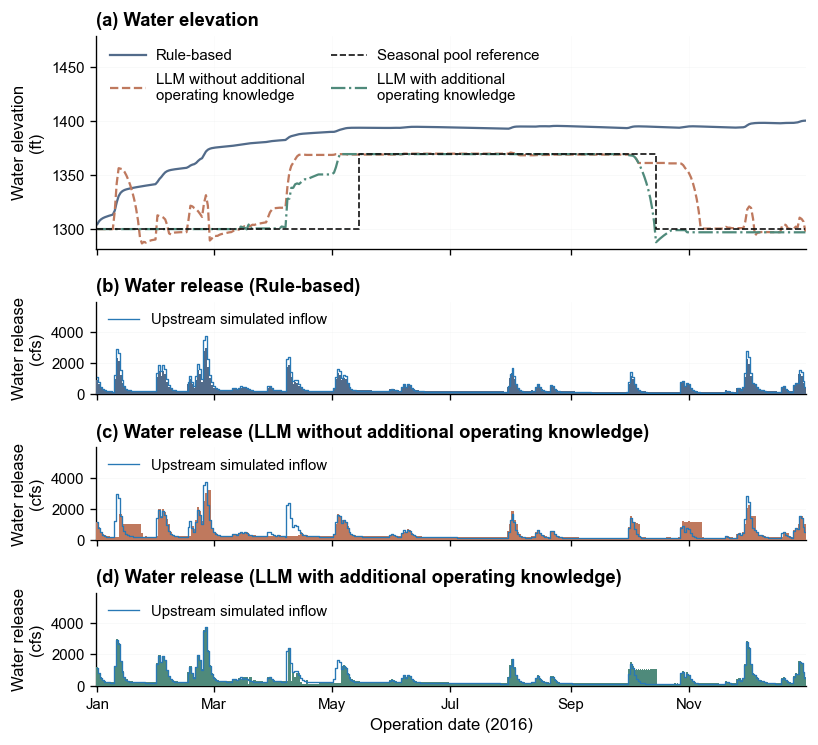

In [7]:
from tutorials.build_notebooks import plot_reservoir_operations
fig = plot_reservoir_operations(daily, seasonal_criteria)
display(fig)

## 6. Run a new experiment deliberately

These commands are documentation and are not executed by this notebook. Copy
the chosen entry, set a new `run_id` and output, then check and prepare before
allowing network use.

```powershell
Copy-Item examples/fe_walter/coupled/llm_available.yaml examples/fe_walter/coupled/my-run.yaml
# Edit my-run.yaml: set a new run_id and output.
reservoir-experiment check examples/fe_walter/coupled/my-run.yaml
reservoir-experiment prepare examples/fe_walter/coupled/my-run.yaml
reservoir-experiment run examples/fe_walter/coupled/my-run.yaml --allow-network
reservoir-experiment verify <new-output-path>/operation
```

Use `experiment.yaml` for Rule-based operation or copy `llm_knowledge.yaml` for
LLM with additional operating knowledge. [Technical engine evidence and historical audits](../examples/fe_walter/engine_comparison.md)
remain outside this main research narrative.